In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%pip install pandas sqlalchemy pymysql
%pip install mysql-connector-python
import pandas as pd
import sqlalchemy
import pymysql

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
df = pd.read_csv(r"C:\Users\Prathamesh\Downloads\Datasets\loans.csv")

In [3]:
df.head()

,loanId,anon_ssn,payFrequency,apr,applicationDate,originated,originatedDate,nPaidOff,approved,isFunded,loanStatus,loanAmount,originallyScheduledPaymentAmount,state,leadType,leadCost,fpStatus,clarityFraudId,hasCF
0,LL-I-07399092,beff4989be82aab4a5b47679216942fd,B,360.0,2016-02-23T17:29:01.940000,False,NaN,0.0,False,0,Withdrawn Application,500.0,978.27,IL,bvMandatory,6,NaN,5669ef78e4b0c9d3936440e6,1
1,LL-I-06644937,464f5d9ae4fa09ece4048d949191865c,B,199.0,2016-01-19T22:07:36.778000,True,2016-01-20T15:49:18.846000,0.0,True,1,Paid Off Loan,3000.0,6395.19,CA,prescreen,0,Checked,569eb3a3e4b096699f685d64,1
2,LL-I-10707532,3c174ae9e2505a5f9ddbff9843281845,B,590.0,2016-08-01T13:51:14.709000,False,NaN,0.0,False,0,Withdrawn Application,400.0,1199.45,MO,bvMandatory,3,NaN,579eab11e4b0d0502870ef2f,1
3,LL-I-02272596,9be6f443bb97db7e95fa0c281d34da91,B,360.0,2015-08-06T23:58:08.880000,False,NaN,0.0,False,0,Withdrawn Application,500.0,1074.05,IL,bvMandatory,3,NaN,555b1e95e4b0f6f11b267c18,1
4,LL-I-09542882,63b5494f60b5c19c827c7b068443752c,B,590.0,2016-06-05T22:31:34.304000,False,NaN,0.0,False,0,Rejected,350.0,814.37,NV,bvMandatory,3,NaN,5754a91be4b0c6a2bf424772,1


In [4]:
df.shape

(576682, 19)

In [5]:
df.columns

Index(['loanId', 'anon_ssn', 'payFrequency', 'apr', 'applicationDate',
       'originated', 'originatedDate', 'nPaidOff', 'approved', 'isFunded',
       'loanStatus', 'loanAmount', 'originallyScheduledPaymentAmount', 'state',
       'leadType', 'leadCost', 'fpStatus', 'clarityFraudId', 'hasCF'],
      dtype='object')

In [6]:
df.dtypes

loanId                               object
anon_ssn                             object
payFrequency                         object
apr                                 float64
applicationDate                      object
originated                             bool
originatedDate                       object
nPaidOff                            float64
approved                               bool
isFunded                              int64
loanStatus                           object
loanAmount                          float64
originallyScheduledPaymentAmount    float64
state                                object
leadType                             object
leadCost                              int64
fpStatus                             object
clarityFraudId                       object
hasCF                                 int64
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 576682 entries, 0 to 576681
Data columns (total 19 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   loanId                            576426 non-null  object 
 1   anon_ssn                          576682 non-null  object 
 2   payFrequency                      575409 non-null  object 
 3   apr                               572760 non-null  float64
 4   applicationDate                   576682 non-null  object 
 5   originated                        576682 non-null  bool   
 6   originatedDate                    45045 non-null   object 
 7   nPaidOff                          576658 non-null  float64
 8   approved                          576682 non-null  bool   
 9   isFunded                          576682 non-null  int64  
 10  loanStatus                        576291 non-null  object 
 11  loanAmount                        574432 non-null  f

In [8]:
df.describe()

,apr,nPaidOff,isFunded,loanAmount,originallyScheduledPaymentAmount,leadCost,hasCF
count,572760.000000,576658.000000,576682.000000,574432.000000,576682.000000,576682.000000,576682.000000
mean,553.130340,0.037187,0.065943,514.009584,1428.289195,7.845608,0.618800
std,110.014932,0.330122,0.248182,320.609549,924.181233,12.824222,0.485682
min,0.000000,0.000000,0.000000,0.000000,-816.710000,0.000000,0.000000
25%,490.000000,0.000000,0.000000,350.000000,1023.640000,3.000000,0.000000
50%,590.000000,0.000000,0.000000,500.000000,1245.250000,3.000000,1.000000
75%,601.000000,0.000000,0.000000,500.000000,1615.660000,6.000000,1.000000
max,705.590000,21.000000,1.000000,5000.000000,19963.630000,200.000000,1.000000


In [9]:
df.isnull().sum()

loanId                                 256
anon_ssn                                 0
payFrequency                          1273
apr                                   3922
applicationDate                          0
originated                               0
originatedDate                      531637
nPaidOff                                24
approved                                 0
isFunded                                 0
loanStatus                             391
loanAmount                            2250
originallyScheduledPaymentAmount         0
state                                  132
leadType                                 0
leadCost                                 0
fpStatus                            525913
clarityFraudId                      219831
hasCF                                    0
dtype: int64

In [10]:
df["loanStatus"]

0         Withdrawn Application
1                 Paid Off Loan
2         Withdrawn Application
3         Withdrawn Application
4                      Rejected
                  ...          
576677    Withdrawn Application
576678    Withdrawn Application
576679    Withdrawn Application
576680    Withdrawn Application
576681                 Rejected
Name: loanStatus, Length: 576682, dtype: object

In [11]:
df["loanAmount"]

0          500.0
1         3000.0
2          400.0
3          500.0
4          350.0
           ...  
576677     400.0
576678    1000.0
576679     300.0
576680     300.0
576681     400.0
Name: loanAmount, Length: 576682, dtype: float64

In [12]:
df["approved"]

0         False
1          True
2         False
3         False
4         False
          ...  
576677    False
576678    False
576679    False
576680    False
576681    False
Name: approved, Length: 576682, dtype: bool

In [13]:
df = df.drop(columns=["anon_ssn"])

In [14]:
df

,loanId,payFrequency,apr,applicationDate,originated,originatedDate,nPaidOff,approved,isFunded,loanStatus,loanAmount,originallyScheduledPaymentAmount,state,leadType,leadCost,fpStatus,clarityFraudId,hasCF
0,LL-I-07399092,B,360.0,2016-02-23T17:29:01.940000,False,NaN,0.0,False,0,Withdrawn Application,500.0,978.27,IL,bvMandatory,6,NaN,5669ef78e4b0c9d3936440e6,1
1,LL-I-06644937,B,199.0,2016-01-19T22:07:36.778000,True,2016-01-20T15:49:18.846000,0.0,True,1,Paid Off Loan,3000.0,6395.19,CA,prescreen,0,Checked,569eb3a3e4b096699f685d64,1
2,LL-I-10707532,B,590.0,2016-08-01T13:51:14.709000,False,NaN,0.0,False,0,Withdrawn Application,400.0,1199.45,MO,bvMandatory,3,NaN,579eab11e4b0d0502870ef2f,1
3,LL-I-02272596,B,360.0,2015-08-06T23:58:08.880000,False,NaN,0.0,False,0,Withdrawn Application,500.0,1074.05,IL,bvMandatory,3,NaN,555b1e95e4b0f6f11b267c18,1
4,LL-I-09542882,B,590.0,2016-06-05T22:31:34.304000,False,NaN,0.0,False,0,Rejected,350.0,814.37,NV,bvMandatory,3,NaN,5754a91be4b0c6a2bf424772,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
576677,LL-I-12122269,B,590.0,2016-11-08T17:32:33.554000,False,NaN,0.0,False,0,Withdrawn Application,400.0,1292.41,NV,bvMandatory,3,NaN,58220cdde4b051c58d919c1f,1
576678,LL-I-16183462,S,490.0,2017-01-24T22:20:59.818000,False,NaN,0.0,False,0,Withdrawn Application,1000.0,2592.39,MO,lead,25,NaN,5887d349e4b08f249ac45e2f,1
576679,LL-I-06962710,B,590.0,2016-02-02T03:05:47.797000,False,NaN,0.0,False,0,Withdrawn Application,300.0,844.75,IN,bvMandatory,6,NaN,550b1f59e4b0d4592e28c84e,1
576680,LL-I-01253468,B,550.0,2015-05-21T20:19:49.639000,False,NaN,0.0,False,0,Withdrawn Application,300.0,770.80,OH,organic,6,NaN,NaN,0


In [15]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
576677    False
576678    False
576679    False
576680    False
576681    False
Length: 576682, dtype: bool

In [16]:
df.isnull().sum()

loanId                                 256
payFrequency                          1273
apr                                   3922
applicationDate                          0
originated                               0
originatedDate                      531637
nPaidOff                                24
approved                                 0
isFunded                                 0
loanStatus                             391
loanAmount                            2250
originallyScheduledPaymentAmount         0
state                                  132
leadType                                 0
leadCost                                 0
fpStatus                            525913
clarityFraudId                      219831
hasCF                                    0
dtype: int64

In [17]:
median_loanAmount = df["loanAmount"].median()
df["loanAmount"] = df["loanAmount"].fillna(median_loanAmount)

In [18]:
df["originatedDate"] = df["originatedDate"].fillna("ffill")

In [19]:
df["clarityFraudId"] = df["clarityFraudId"].fillna("Unknown")

In [20]:
df.isnull().sum()

loanId                                 256
payFrequency                          1273
apr                                   3922
applicationDate                          0
originated                               0
originatedDate                           0
nPaidOff                                24
approved                                 0
isFunded                                 0
loanStatus                             391
loanAmount                               0
originallyScheduledPaymentAmount         0
state                                  132
leadType                                 0
leadCost                                 0
fpStatus                            525913
clarityFraudId                           0
hasCF                                    0
dtype: int64

In [21]:
df

,loanId,payFrequency,apr,applicationDate,originated,originatedDate,nPaidOff,approved,isFunded,loanStatus,loanAmount,originallyScheduledPaymentAmount,state,leadType,leadCost,fpStatus,clarityFraudId,hasCF
0,LL-I-07399092,B,360.0,2016-02-23T17:29:01.940000,False,ffill,0.0,False,0,Withdrawn Application,500.0,978.27,IL,bvMandatory,6,NaN,5669ef78e4b0c9d3936440e6,1
1,LL-I-06644937,B,199.0,2016-01-19T22:07:36.778000,True,2016-01-20T15:49:18.846000,0.0,True,1,Paid Off Loan,3000.0,6395.19,CA,prescreen,0,Checked,569eb3a3e4b096699f685d64,1
2,LL-I-10707532,B,590.0,2016-08-01T13:51:14.709000,False,ffill,0.0,False,0,Withdrawn Application,400.0,1199.45,MO,bvMandatory,3,NaN,579eab11e4b0d0502870ef2f,1
3,LL-I-02272596,B,360.0,2015-08-06T23:58:08.880000,False,ffill,0.0,False,0,Withdrawn Application,500.0,1074.05,IL,bvMandatory,3,NaN,555b1e95e4b0f6f11b267c18,1
4,LL-I-09542882,B,590.0,2016-06-05T22:31:34.304000,False,ffill,0.0,False,0,Rejected,350.0,814.37,NV,bvMandatory,3,NaN,5754a91be4b0c6a2bf424772,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
576677,LL-I-12122269,B,590.0,2016-11-08T17:32:33.554000,False,ffill,0.0,False,0,Withdrawn Application,400.0,1292.41,NV,bvMandatory,3,NaN,58220cdde4b051c58d919c1f,1
576678,LL-I-16183462,S,490.0,2017-01-24T22:20:59.818000,False,ffill,0.0,False,0,Withdrawn Application,1000.0,2592.39,MO,lead,25,NaN,5887d349e4b08f249ac45e2f,1
576679,LL-I-06962710,B,590.0,2016-02-02T03:05:47.797000,False,ffill,0.0,False,0,Withdrawn Application,300.0,844.75,IN,bvMandatory,6,NaN,550b1f59e4b0d4592e28c84e,1
576680,LL-I-01253468,B,550.0,2015-05-21T20:19:49.639000,False,ffill,0.0,False,0,Withdrawn Application,300.0,770.80,OH,organic,6,NaN,Unknown,0


In [22]:
df["loanStatus"] = df["loanStatus"].str.upper()

In [23]:
df.sample(5)

,loanId,payFrequency,apr,applicationDate,originated,originatedDate,nPaidOff,approved,isFunded,loanStatus,loanAmount,originallyScheduledPaymentAmount,state,leadType,leadCost,fpStatus,clarityFraudId,hasCF
450446,LL-I-15119786,S,645.0,2017-01-13T14:43:04.939000,False,ffill,0.0,False,0,REJECTED,400.0,854.10,FL,bvMandatory,6,NaN,5878e8b3e4b08f2482d4ea0d,1
174250,LL-I-05887089,W,360.0,2015-12-18T18:53:53.547000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,325.0,689.76,IL,bvMandatory,6,NaN,Unknown,0
327473,LL-I-12867016,W,645.0,2016-12-10T23:23:03.015000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,350.0,1212.73,AL,bvMandatory,3,NaN,Unknown,0
538347,LL-I-16041194,B,680.0,2017-01-22T16:17:07.903000,False,ffill,0.0,False,0,REJECTED,500.0,1835.75,TX,bvMandatory,3,NaN,5884dccce4b08f24965e2a0d,1
476076,LL-I-17132734,S,680.0,2017-02-14T11:17:03.847000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,300.0,1296.10,TX,bvMandatory,3,NaN,Unknown,0


# Standardize Column Name

In [24]:
df.rename(columns= {
    "loanId":"LoanId",
    "payFrequency":"PayFrequency",
    "apr":"APR",
    "applicationDate":"ApplicationDate",
    "originated":"Originated",
    "originatedDate":"OriginatedDate",
    "approved":"Approved",
    "loanStatus":"LoanStatus",
    "loanAmount":"LoanAmount",
    "originallyScheduledPaymentAmount":"OriginallyScheduledPaymentAmount",
    "state":"State",
    "leadType":"LeadType",
    "leadCost":"LeadCost",
    "clarityFraudId":"ClarityFraudId"
},inplace = True)

In [25]:
df.sample(5)

,LoanId,PayFrequency,APR,ApplicationDate,Originated,OriginatedDate,nPaidOff,Approved,isFunded,LoanStatus,LoanAmount,OriginallyScheduledPaymentAmount,State,LeadType,LeadCost,fpStatus,ClarityFraudId,hasCF
284609,LL-I-06832334,B,590.0,2016-01-27T13:44:54.872000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,500.0,1309.98,TN,bvMandatory,6,NaN,56a8c9a2e4b0753d957c6060,1
327959,LL-I-16650847,W,680.0,2017-02-02T22:20:33.393000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,400.0,1449.67,TX,bvMandatory,3,NaN,Unknown,0
47102,LL-I-00006282,B,NaN,2014-12-08T03:02:29.793000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,900.0,2159.08,OH,lead,6,NaN,Unknown,0
574777,LL-I-09921104,M,650.0,2016-06-23T04:09:16.920000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,350.0,895.47,TN,bvMandatory,3,NaN,566f7855e4b05a5e4f58334f,1
259071,LL-I-11969012,B,360.0,2016-09-13T13:15:49.041000,False,ffill,0.0,False,0,WITHDRAWN APPLICATION,500.0,1054.99,IL,bvMandatory,10,NaN,5743862be4b061d2a7d250d6,1


In [26]:
df.shape

(576682, 18)

# DATA VISUALIZATION

 **1. Count Plot – Loan Status Distribution**

*The count plot shows the distribution of loans across different loan status categories. It helps identify which loan statuses have the highest and lowest number of loans in the dataset.*

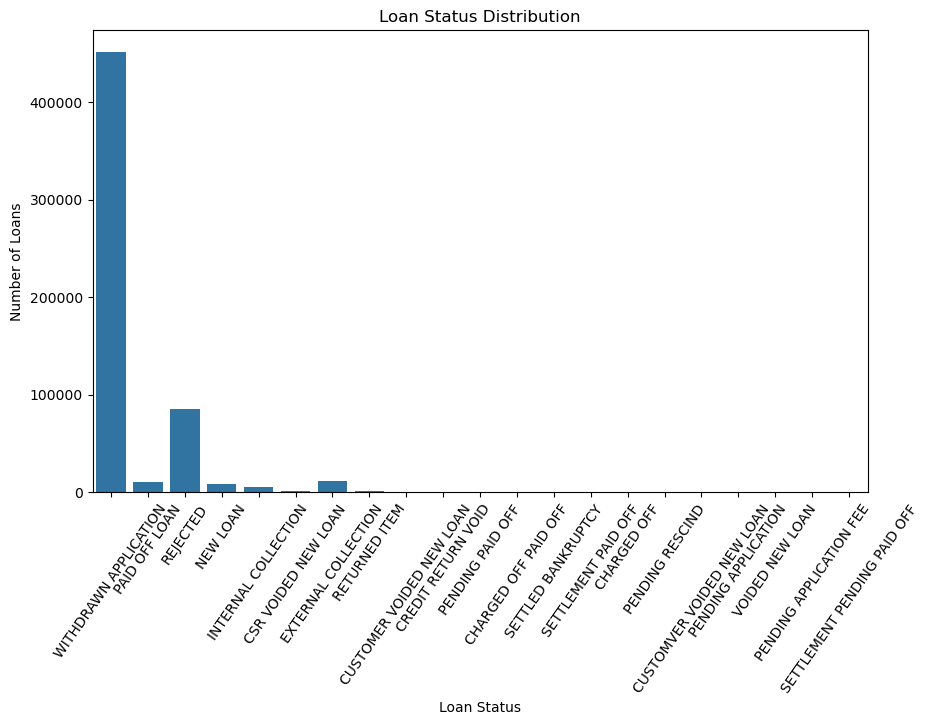

In [27]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="LoanStatus")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=55)

plt.show()

**2.Histogram – APR Distribution**

*The histogram shows the distribution of APR (Annual Percentage Rate) values in the dataset. It helps identify the most common APR ranges and how frequently they occur. The purple bars make it easy to observe the spread and concentration of APR values.*


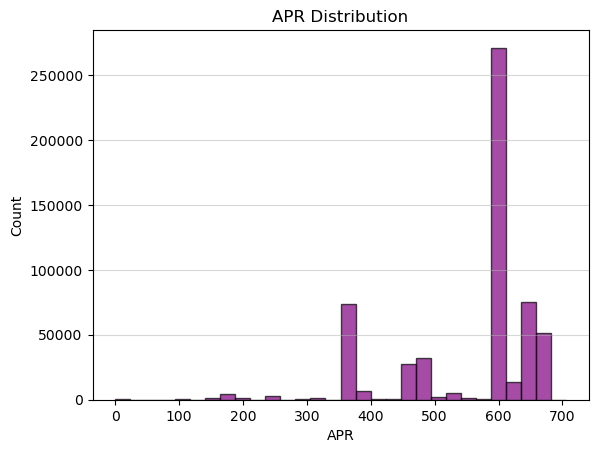

In [28]:
plt.hist(data=df,
         x="APR",
         bins = 30,
         color = "purple",
         edgecolor = "black",
         alpha = 0.7
        )
plt.title("APR Distribution")
plt.xlabel("APR")
plt.ylabel("Count")
plt.grid(axis = "y", alpha = 0.5)
plt.show()

**3.Count Plot – Loan Approval Count**

*The count plot shows the number of loans that were approved and not approved. It helps compare the total count of approved and rejected loan applications. This visualization provides a clear overview of the loan approval rate in the dataset.*


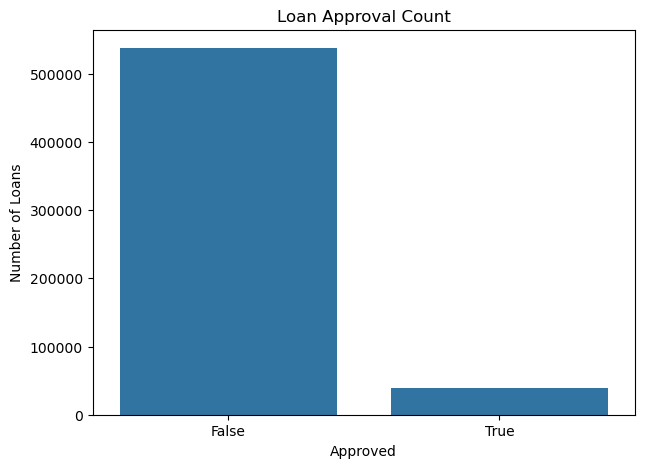

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Approved")

plt.title("Loan Approval Count")
plt.xlabel("Approved")
plt.ylabel("Number of Loans")

plt.show()

**4.Bar Plot – Average Number of Loans Paid Off by Funding Status**

* *The bar plot compares the average number of loans paid off (`nPaidOff`) across funding status categories (`isFunded`). It helps identify how loan repayment history differs between funded and non-funded loans. This visualization can reveal a relationship between previous loan repayments and funding status.*


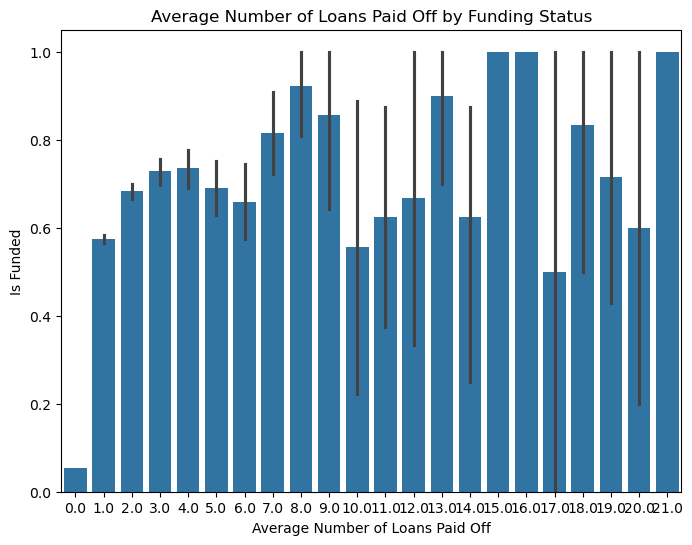

In [30]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="nPaidOff",
    y="isFunded",
    estimator="mean"
)

plt.title("Average Number of Loans Paid Off by Funding Status")
plt.xlabel("Average Number of Loans Paid Off")
plt.ylabel("Is Funded")

plt.show()

**5. Scatter Plot – Loan Amount vs APR**

* *The scatter plot shows the relationship between loan amount and APR (Annual Percentage Rate). It helps identify whether higher loan amounts are associated with higher or lower APR values. Each point represents a loan, making it easier to observe patterns, clusters, and outliers in the dataset.*


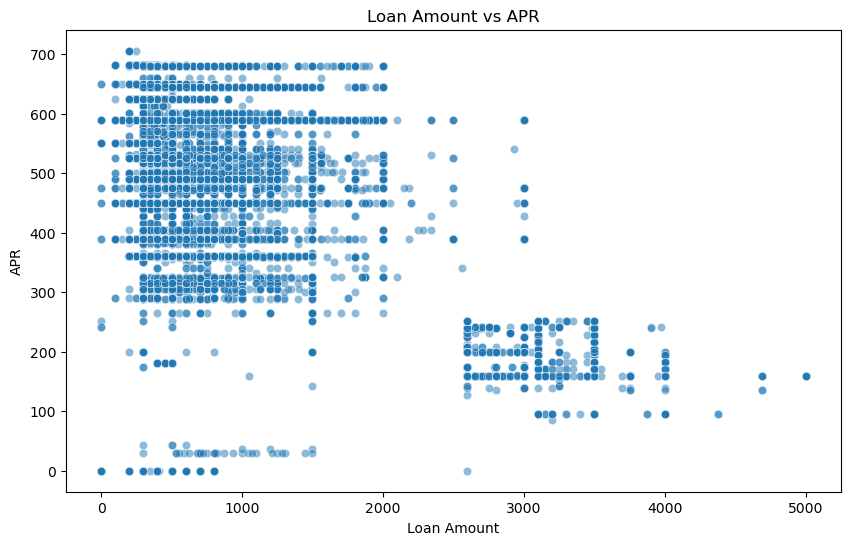

In [31]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="LoanAmount",
    y="APR",
    alpha=0.5
)

plt.title("Loan Amount vs APR")
plt.xlabel("Loan Amount")
plt.ylabel("APR")
plt.show()

**6. Pie Chart – Pay Frequency Distribution**

* *The pie chart shows the distribution of different payment frequencies in the dataset. It displays the percentage of loans for each payment frequency, making comparisons easy. This visualization helps identify the most and least common payment frequencies among borrowers.*


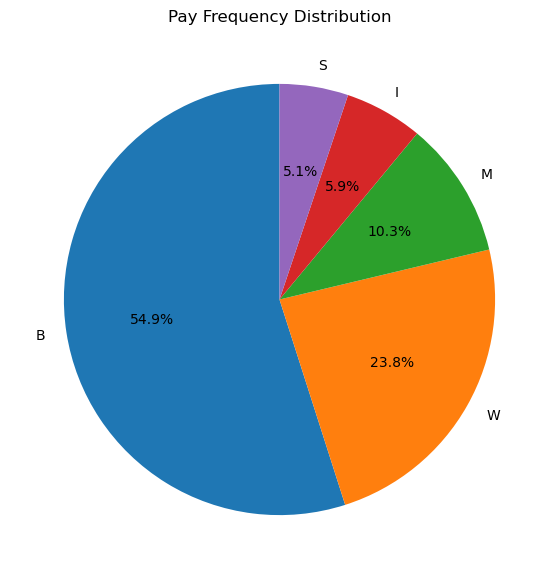

In [32]:
PayFrequency_counts = df["PayFrequency"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    PayFrequency_counts.values,
    labels=PayFrequency_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Pay Frequency Distribution")
plt.show()

**7. Heatmap – Correlation Heatmap**

* *The correlation heatmap shows the relationship between the selected numerical variables in the dataset.
Values closer to **+1 or -1** indicate a strong correlation, while values near **0** indicate a weak relationship.
It helps identify which variables are strongly or weakly related to each other.*


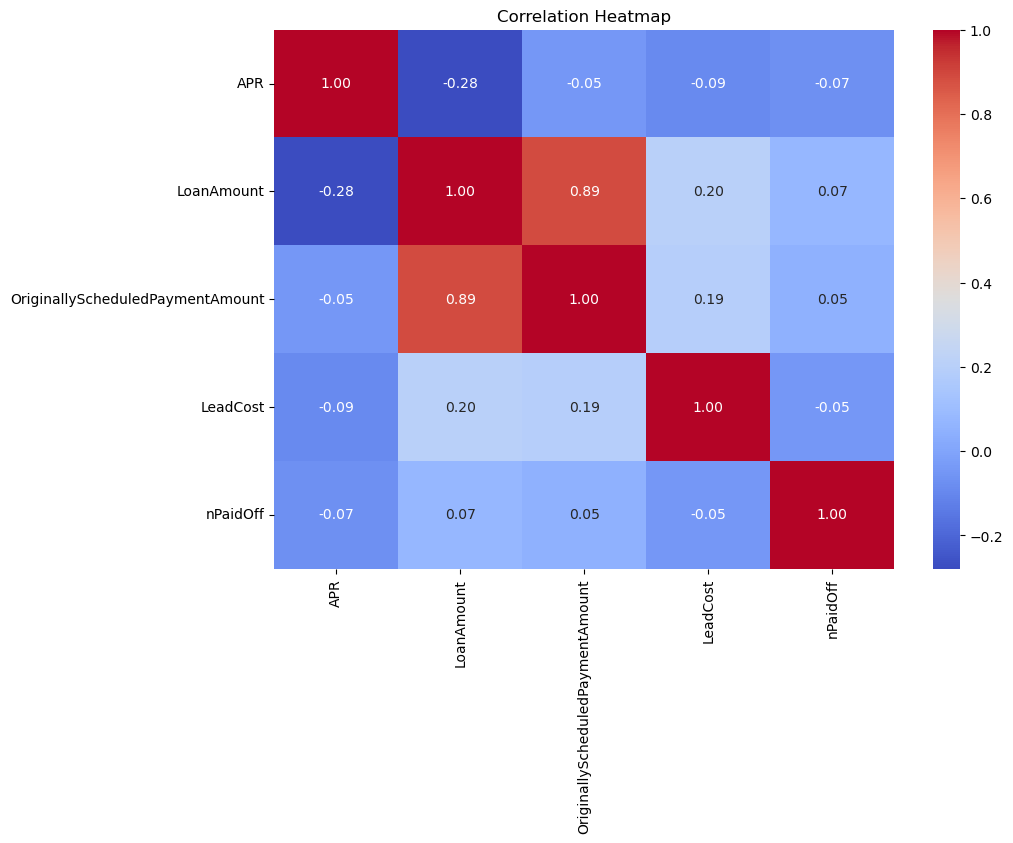

In [33]:
numeric_cols = [
    "APR",
    "LoanAmount",
    "OriginallyScheduledPaymentAmount",
    "LeadCost",
    "nPaidOff"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# MySQL Connection

In [40]:
df.to_csv("Loan Analysis Project.csv",index=False)

In [34]:
from sqlalchemy import create_engine

username = "root"
password = "1323"
host = "localhost"
database = "bank_loan"

engine = create_engine(
    f"mysql+pymysql://{username}:{password}@{host}:3306/{database}"
)

# Test MySQL connection
with engine.connect() as connection:
    print("MySQL connected successfully!")

MySQL connected successfully!


# Uploading Data to MySQL

In [39]:
df.to_sql(
    "loans",
    con=engine,
    if_exists="replace",
    index=False
)

print("loans uploaded successfully!")

loans uploaded successfully!
